In [1]:
# 1A. Implement Feedforward Neural Network (FNN) with Keras and TensorFlow for
# classification of hand-written MNIST dataset using below steps:
# a. Import the necessary packages
# b. Load the training and testing data
# c. Define the network architecture using Keras
# d. Train the model using SGD with 11 epochs
# e. Evaluate the network
# f. Plot the training loss and accuracy

# Load → Normalize → Encode → Build → Compile → Train → Evaluate → Predict → Plot

In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import LabelBinarizer

In [2]:
# Load
train_data = pd.read_csv("/Users/aayushagarwal/Downloads/LP IV Updated Datasets/FNN and CNN/Fashion MNIST/fashion-mnist_train.csv")
test_data = pd.read_csv("/Users/aayushagarwal/Downloads/LP IV Updated Datasets/FNN and CNN/Fashion MNIST/fashion-mnist_test.csv")

x_train = train_data.drop("label" , axis = 1).values.reshape(-1 , 28 , 28 , 1)
x_test = test_data.drop("label" , axis = 1).values.reshape(-1 , 28 , 28 , 1)
y_train = train_data["label"].values
y_test = test_data["label"].values

In [3]:
# Normalize : 

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

lb = LabelBinarizer()
y_train = lb.fit_transform(y_train)
y_test = lb.transform(y_test)

In [4]:
model = keras.Sequential([
    keras.layers.Input(shape= x_train.shape[1:]),
    keras.layers.Flatten(),
    keras.layers.Dense(128 , activation="relu"),
    keras.layers.Dense(10 , activation="softmax")
])

In [5]:
# Compile : 
model.compile(optimizer= keras.optimizers.SGD(learning_rate=0.01) , loss="categorical_crossentropy" , metrics=["accuracy"])

In [6]:
# Train : 
history = model.fit(
    x_train , y_train , epochs = 11 , batch_size = 32 , validation_split = 0.2
)

Epoch 1/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 578us/step - accuracy: 0.7521 - loss: 0.7774 - val_accuracy: 0.8036 - val_loss: 0.5844
Epoch 2/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 506us/step - accuracy: 0.8190 - loss: 0.5324 - val_accuracy: 0.8267 - val_loss: 0.5101
Epoch 3/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 512us/step - accuracy: 0.8320 - loss: 0.4854 - val_accuracy: 0.8370 - val_loss: 0.4800
Epoch 4/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 514us/step - accuracy: 0.8395 - loss: 0.4582 - val_accuracy: 0.8377 - val_loss: 0.4661
Epoch 5/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 513us/step - accuracy: 0.8456 - loss: 0.4399 - val_accuracy: 0.8478 - val_loss: 0.4453
Epoch 6/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 516us/step - accuracy: 0.8519 - loss: 0.4259 - val_accuracy: 0.8489 - val_loss: 0.4363
Epoch 7/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 511us/step - accuracy: 0.8547 - loss: 0.4129 - val_accuracy: 0.8492 - val_loss: 0.4336
Epoch 8/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 515us/step - accuracy: 0.8595 -

In [7]:
# Evaluate : 
loss , accuracy = model.evaluate(x_test , y_test , verbose = 0)
print(loss)
print(accuracy)

0.3876570165157318
0.8662999868392944


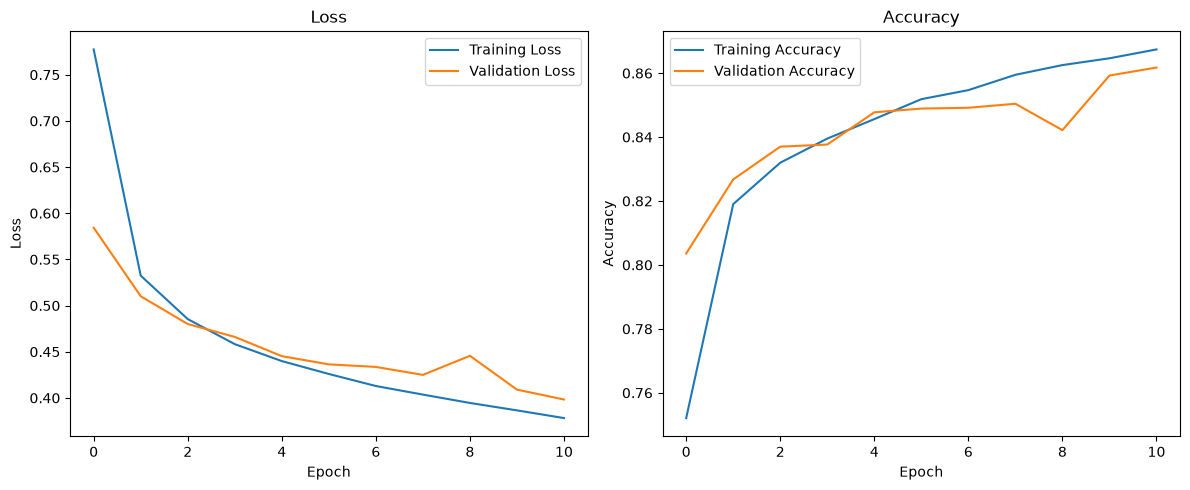

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()